# Binary classification


## Bài toán
Cho tập dữ liệu là mức lương hằng tháng của $15$ sinh viên vừa tốt nghiệp đại học (triệu VND). Dựa vào dữ liệu này để dự đoán xem các sinh viên có hạnh phúc với mức sống hiện tại hay không.

**Lưu ý**: Đề bài, số liệu chỉ mang tính chất minh họa.

## Đọc và visualize dữ liệu

In [1]:
import random
import numpy as np
from mlxtend.plotting import plot_decision_regions
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
# Dữ liệu mẫu
# Mức lương sinh viên nhận được (triệu VND/tháng)
x = np.array([2, 3, 5, 7, 10, 11, 12, 13, 14, 16, 17, 18, 20, 22, 23])
# Nhãn tương ứng  (0: không hạnh phúc, 1: hạnh phúc)
y = np.array([0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1])

In [2]:
# Reshape x để khớp input của mô hình
X = x.reshape(-1,1)
print(X.shape, y.shape)

(15, 1) (15,)


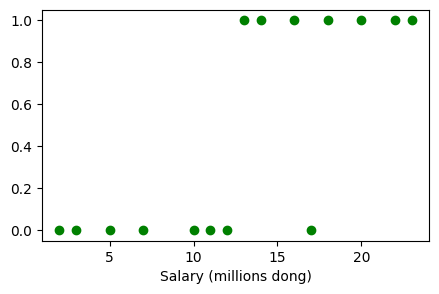

In [3]:
# Visualize tập dữ liệu
plt.figure(figsize=(5, 3))
plt.scatter(x, y, color='g')
plt.xlabel('Salary (millions dong)')
plt.show()

## Chạy thử với mô hình Linear Regression

In [4]:
import numpy as np
import matplotlib.pyplot as plt

In [5]:
# Mức lương sinh viên nhận được (triệu VND/tháng)
x = np.array([2, 3, 5, 7, 10, 11, 12, 13, 14, 16, 17, 18, 20, 22, 23])
# Nhãn tương ứng  (0: không hạnh phúc, 1: hạnh phúc)
y = np.array([0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1])

# Reshape x để khớp input của mô hình
X = x.reshape(-1,1)
print(X.shape)

(15, 1)


In [6]:
# Test trường hợp xuất hiện 1 điểm outlier
# Xuất hiện 1 sinh viên có mức lương 38 triệu (cao hơn nhiều so với những sinh viên còn lại) và hạnh phúc

# Bỏ comment đoạn code bên dưới và chạy lại để xem kết quả dự đoán thay đổi

# x = np.array([2, 3, 5, 7, 10, 11, 12, 13, 14, 16, 17, 18, 20, 22, 23, 38])
# y = np.array([0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1])
# X = x.reshape(-1,1)


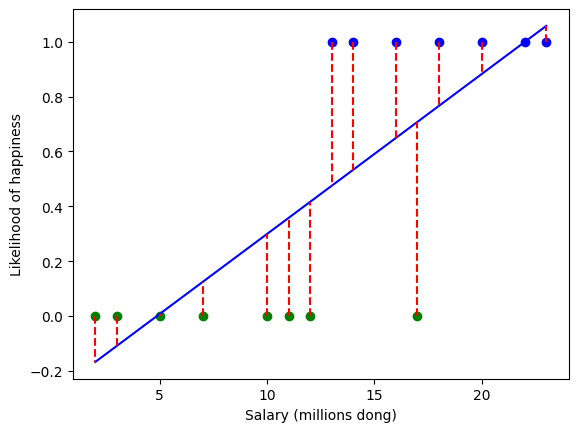

In [7]:
# Fit và dự đoán với mô hình Linear Regression
X_with_bias = np.hstack((np.ones((X.shape[0], 1)), X)) # Thêm cột 1 vào dữ liệu

W = np.linalg.inv(X_with_bias.T @ X_with_bias) @ (X_with_bias.T @ y) # Tính W theo công thức

X_range = np.linspace(min(x), max(x), 100) 
X_range_with_bias = np.hstack((np.ones((X_range.shape[0], 1)), X_range.reshape(-1, 1)))
y_predicted = X_range_with_bias @ W

#  chia tập dữ liệu thành 2 nhãn 0 và 1
X_1,X_0,y_1,y_0 = X[y == 1], X[y == 0], y[y == 1], y[y == 0]

plt.scatter(X_0, y_0, color='g')
plt.scatter(X_1, y_1, color='b')
plt.plot(X_range, y_predicted, color='b')
plt.vlines(x, ymin=y, ymax=(X_with_bias @ W), color='r', linestyle='dashed')
plt.xlabel('Salary (millions dong)')
plt.ylabel('Likelihood of happiness')
plt.show()


## Logistic Regression from scratch


### Ký hiệu và hàm toán học



- $N$ số lượng điểm trong tập dữ liệu.
- $x_i$ thuộc tính của điểm dữ liệu thứ $i$.
- $y_i$ nhãn của điểm dữ liệu thứ $i$.
- $\hat{y_i}$ xác suất dự đoán nhãn của điểm dữ liệu thứ $i$.
- $w, b$ weights và bias của mô hình.

Hàm mất mát (cross-entropy loss)

$$\mathcal{L}(\hat{y}, y) = -\frac{1}{N}\sum_{i=1}^N y_ilog(\hat{y_i})+(1-y_i)log(1-\hat{y_i}) $$

Gradient của hàm mất mát

$$\nabla_{w}\mathcal{L}(w) = \frac{1}{N} X^T(\hat{y} - y)$$

Hàm dự đoán (sigmoid function)
$$z = X*w$$
$$g(z) = \frac{1}{1 + e^{-z}}$$

In [8]:
# Hàm sigmoid
def sigmoid(z):
  return 1 / (1 + np.exp(-z))

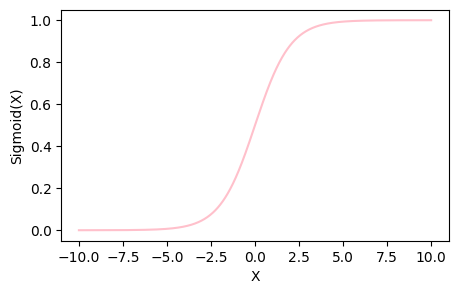

In [9]:
# Visualize hàm sigmoid 
lin_x = np.linspace(-10, 10, 1000)

plt.figure(figsize=(5, 3))
plt.plot(lin_x, sigmoid(lin_x), color='pink')
plt.xlabel("X")
plt.ylabel("Sigmoid(X)")

plt.show()

In [10]:
# Hàm accuracy
def acc(y_hat, y):
    return np.sum(y_hat == y) / len(y)

### Model

**Giải thích class LogisticRegression_Scratch**


+ *fit*: 
    + *np.hstack(...)*: thêm một cột 1 nữa vào X để tính toán bias tiện lợi.
    + Lấy các chiều.
    + Khởi tạo W (bao gồm bias).
    + Reshape lại y.
    + Gradient Descent.
+ *cal_grad*: Tính toán gradient descent dựa trên công thức $$\nabla_{w}\mathcal{L}(w) = \frac{1}{N} X^T(\hat{y} - y)$$
+ *predict_proba*:
    + *np.hstack(...)*: thêm một cột 1 nữa vào X để tính toán bias tiện lợi.
    + Tính toán `y_hat`.
+ *predict*: 
    + tính `predict_proba`
    + Nếu `> threshold` thì là 1, ngược lại là 0. 




In [11]:
import numpy as np
def sigmoid(z: np.ndarray):
    return 1 / (1 + np.exp(-z))

class LogisticRegression_Scratch:
    def __init__(self, lr = 0.01, iterations = 1000):
        self.lr = lr
        self.iterations = iterations

    def fit(self, X: np.ndarray, y:np.ndarray):
        self.X = np.hstack((np.ones((X.shape[0], 1)), X))  # (m, n)
        self.m = self.X.shape[0]
        self.n = self.X.shape[1]
        
        self.W = np.zeros(self.n) # (n)
        self.y = y.reshape(-1, 1) # (m, 1)
        
        # Gradient Descent
        for _ in range(self.iterations):
            grad_w = self.cal_grad()
            self.W -= self.lr * grad_w
        return self
 
    def cal_grad(self):
        y_hat = sigmoid(self.X@self.W).reshape(-1, 1)  # (m, 1)
        grad = (self.X.T @ (y_hat - self.y)).squeeze() / self.m  # (n)
        return grad

    def predict_proba(self, X:np.ndarray):
        X = np.hstack((np.ones((X.shape[0], 1)), X))
        return sigmoid(X@self.W)
    
    def predict(self, X:np.ndarray, threshold = 0.5):
        y_hat = self.predict_proba(X)
        return np.where(y_hat > threshold, 1, 0)

### Visualization - Logistic Regression from Scratch

In [12]:
# Có thể tự chỉnh giá trị learning rate (lr) và số lần lặp (iterations)
# để quan sát kết quả thay đổi
lrmodel = LogisticRegression_Scratch(lr = 0.005, iterations = 100_000)
lrmodel.fit(X, y)

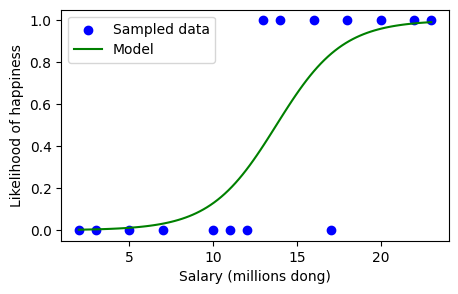

In [13]:
X_range = np.linspace(np.min(X), np.max(X), 100).reshape(-1, 1)
y_range = lrmodel.predict_proba(X_range).reshape(-1)

plt.figure(figsize=(5, 3))
plt.scatter(X, y, color='blue', label='Sampled data')
plt.plot(X_range, y_range, color='green', label='Model')
plt.xlabel('Salary (millions dong)')
plt.ylabel('Likelihood of happiness')
plt.legend()
plt.show()

<Axes: >

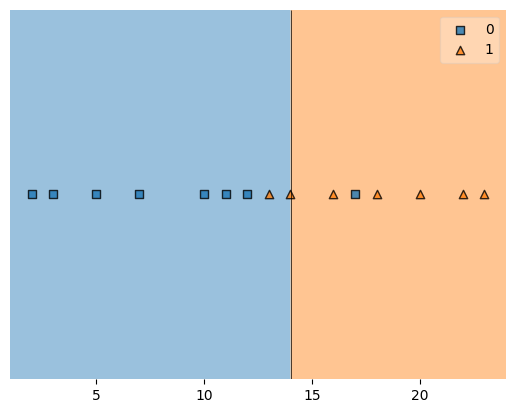

In [14]:
plot_decision_regions(X, y, lrmodel)

Chia tập dữ liệu thành các tập train, test để huấn luyện và đánh giá model

In [15]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 11)

In [16]:
lrmodel = LogisticRegression_Scratch(iterations=10**5)
lrmodel.fit(X_train, y_train)
y_pred_train = lrmodel.predict(X_train)
print('Train accuracy: ', acc(y_pred_train, y_train))
y_pred_test = lrmodel.predict(X_test)
print('Test accuracy: ', acc(y_pred_test, y_test))

Train accuracy:  0.8333333333333334
Test accuracy:  0.6666666666666666


In [17]:
print('Model parameters:', lrmodel.W)

Model parameters: [-7.45860899  0.5130239 ]


## Sklearn


In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

In [19]:
# Chia tập train, test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=11)

In [20]:
# Tạo model
lrmodel = LogisticRegression(max_iter=1000, penalty=None)

In [21]:
# Train model
lrmodel.fit(X_train, y_train)

LogisticRegression(max_iter=1000, penalty=None)

In [22]:
# Dự đoán
y_pred = lrmodel.predict(X_test)
print(y_pred)

[0 0 1]


In [23]:
# Tính accuracy
y_pred_train = lrmodel.predict(X_train)
print('Train accuracy: ', acc(y_pred_train, y_train))
y_pred_test = lrmodel.predict(X_test)
print('Test accuracy: ', acc(y_pred_test, y_test))

Train accuracy:  0.8333333333333334
Test accuracy:  0.6666666666666666


In [24]:
print('Model parameters: ', lrmodel.intercept_, lrmodel.coef_)

Model parameters:  [-7.49677335] [[0.51554014]]


# Multi class classification


## Bài toán

Giả sử tại trường $ABC$ và ở đó đào tạo 3 hệ: ***Đại trà, CLC*** và ***Tài năng***. Giả sử ở đây ta có 15 thí sinh biết gia cảnh người đó (thể hiển qua số **tiền** họ có) và **điểm thi** của thí sinh đó. Nhiệm vụ của chúng ta là phân loại xem thí sinh đó sẽ được học ở hệ đào tạo nào của trường $ABC$.

**Lưu ý**: Đề bài, số liệu chỉ mang tính chất minh họa.


**Dữ liệu:**
- Các samples là một cặp ($X_0$, $X_1$). Trong đó, $X_0$ thể hiện cho điểm thi của thí sinh đó. Và $X_1$ biểu diễn cho số tiền của thí sinh đó.
- Labels của các samples đó là $[0, 1, 2]$ trong đó $0, 1, 2$ lần lượt là các hệ Đại trà, CLC và Tài năng.

## Đọc và visualize dữ liệu

In [25]:
np.random.seed(1112)
X_train = np.array([
 [65, 46],
 [50, 77],
 [70, 33],
 [77, 67],
 [55, 89],
 [78, 33],
 [79, 89],
 [65, 81],
 [47, 68],
 [48, 85],
 [74, 94],
 [93, 86]])
y_train = np.array([0, 1, 0, 0, 1, 0, 2, 1, 1, 1, 2, 2])
X_test = np.array([
 [56, 35],
 [56, 83],
 [80, 89],
])
y_test = np.array([0,1,2])

In [26]:
df = pd.DataFrame(np.hstack([X_train, y_train[:, None]]), columns=['GPA', 'Income', 'Label'])
df['Label'] = df['Label'].map({
    0: 'Hệ Đại trà', 
    1: 'Hệ CLC', 
    2: 'Hệ Tài năng',
})
df

,GPA,Income,Label
0,65,46,Hệ Đại trà
1,50,77,Hệ CLC
2,70,33,Hệ Đại trà
3,77,67,Hệ Đại trà
4,55,89,Hệ CLC
5,78,33,Hệ Đại trà
6,79,89,Hệ Tài năng
7,65,81,Hệ CLC
8,47,68,Hệ CLC
9,48,85,Hệ CLC


<Axes: xlabel='GPA', ylabel='Income'>

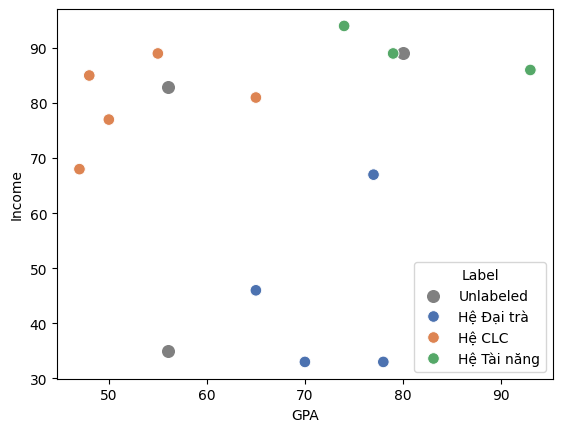

In [27]:
plt.scatter(X_test[:, 0], X_test[:, 1], c='grey', s=70, label='Unlabeled')
sns.scatterplot(df, x='GPA', y='Income', hue='Label', palette="deep", s=70)

## Logistic Regression for multiclass from scratch

### Ký hiệu và hàm toán học

$C$: Số class cần phân loại

$\hat{y}_c^{(i)}$: Xác suất điểm $(i)$ thuộc lớp $c$ (được tính thông qua hàm softmax)

Hàm Softmax:

$$\sigma{(z^{(i)}_{c})} = \frac{e^{z^{(i)}_{c}}}{\sum_{j=1}^C e^{z^{(i)}_{j}}}$$

Hàm mất mát (Cross-entropy)

$$\mathcal{L} = \frac{-1}{N} \sum_{i=1}^N \sum_{c=1}^C y_c^{(i)}log(\hat{y}_c^{(i)})$$


Đạo hàm của hàm mất mát:
$$\nabla_W\mathcal{L} = \frac{1}{N} X^T(\hat{Y} - Y)$$

Ở đây $X$ đã có cột bias; $Y$ là ma trận nhãn one-hot và $\hat{Y}$ là ma trận xác suất softmax, cùng kích thước $N \times C$.


### Model

**Giải thích class MultiClassLogisticRegression**

+ *fit*: 
    + *np.hstack(...)*: thêm một cột 1 nữa vào X để tính toán bias tiện lợi.
    + Lấy các chiều.
    + lấy số class
    + Khởi tạo W (bao gồm bias).
    + OnehotEncoding `y` để lấy được `y_enc`.
    + Gradient Descent.

+ *cal_grad*: Tính toán gradient descent dựa trên công thức $$\nabla_W\mathcal{L} = \frac{1}{N} X^T(\hat{Y} - Y)$$
+ *CE_loss*: Tính toán cross entropy loss dựa trên công thức
$$\mathcal{L} = \frac{-1}{N} \sum_{i=1}^N \sum_{c=1}^C y_c^{(i)}log(\hat{y}_c^{(i)})$$
+ *predict_proba*:
    + *np.hstack(...)*: thêm một cột 1 nữa vào X để tính toán bias tiện lợi.
    + Tính toán `y_hat`.
+ *predict*: 
    + Tính toán predict_proba
    + Class nào có proba lớn nhất thì cho lớp đó làm nhãn
+ *score*: tính score (accuracy)



In [28]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder

def softmax(z):
    # Trừ max trên mỗi dòng để tránh overflow; xác suất không thay đổi.
    shifted = z - np.max(z, axis=1, keepdims=True)
    exp_z = np.exp(shifted)
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)

class MultiClassLogisticRegression:
    def __init__(self, lr = 0.01, iterations = 1000):
        self.lr = lr
        self.iterations = iterations
    
    def fit(self, X: np.ndarray, y:np.ndarray):
        self.X = np.hstack((np.ones((X.shape[0], 1)), X))  # (m, n)
        self.m = self.X.shape[0]
        self.n = self.X.shape[1]
        self.classes = np.unique(y)
        
        self.W = np.zeros(shape=(self.n, len(self.classes))) # (n, c)
        
        self.y_enc = OneHotEncoder(sparse_output=False).fit_transform(y.reshape(-1, 1)) # (m, c)
        
        # Gradient Descent
        for i in range(self.iterations):
            grad_W = self.cal_grad()
            self.W -= self.lr * grad_W
        
        return self
    
    def cal_grad(self): 
        y_hat = softmax(self.X @ self.W)  # (m, c)
        grad = (self.X.T @ (y_hat - self.y_enc))/ self.m  # (n,c)
        return grad
    
    def CE_loss(self, X:np.ndarray, y:np.ndarray): 
        # y là ma trận nhãn one-hot. Tính log-softmax trực tiếp để tránh log(0).
        X_with_bias = np.hstack((np.ones((X.shape[0], 1)), X))
        logits = X_with_bias @ self.W
        shifted = logits - np.max(logits, axis=1, keepdims=True)
        log_probs = shifted - np.log(np.sum(np.exp(shifted), axis=1, keepdims=True))
        loss = np.mean(-np.sum(y * log_probs, axis=1))
        return loss

    def predict_proba(self, X:np.ndarray):
        X = np.hstack((np.ones((X.shape[0], 1)), X))
        return softmax( X @ self.W ) # (m, c)
        
    def predict(self, X:np.ndarray):
        self.probs = self.predict_proba(X) # (m, c) 
        return np.vectorize(lambda c: self.classes[c])(np.argmax(self.probs, axis=1)) # (m)

    def score(self, X:np.ndarray, y:np.ndarray):
        return np.mean(self.predict(X) == y) # (m)

In [29]:
model = MultiClassLogisticRegression(iterations=1_000_000, lr=0.005)
model.fit(X_train, y_train)

In [30]:
# model.fit(X_train, y_train)
y_pred = model.predict_proba(X_test)
print("Xác suất ở mỗi lớp là: ")
print(y_pred)

print("Lớp dự đoán: ")
class_pred = model.predict(X_test)
print(class_pred)

print("Lớp thật sự: ")
print(y_test)

print("Acc =", model.score(X_test, y_test))

Xác suất ở mỗi lớp là: 
[[1.00000000e+00 1.93322432e-26 3.42579147e-32]
 [1.07837629e-59 9.99388642e-01 6.11358037e-04]
 [5.07670562e-31 3.16933364e-03 9.96830666e-01]]
Lớp dự đoán: 
[0 1 2]
Lớp thật sự: 
[0 1 2]
Acc = 1.0


### Visualization

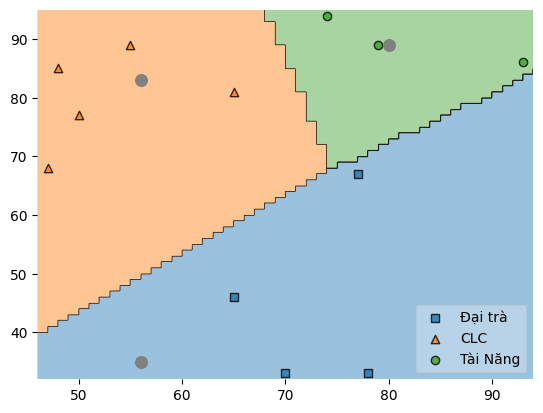

In [31]:
ax = plot_decision_regions(X_train, y_train, model)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, 
          ['Đại trà', 'CLC', 'Tài Năng'], 
           framealpha=0.3, scatterpoints=1)
plt.scatter(X_test[:, 0], X_test[:, 1], c='grey', s=70)

## Sklearn

In [32]:
lrmodel = LogisticRegression(max_iter=100_000, fit_intercept=True, penalty=None)
lrmodel.fit(X_train, y_train)

LogisticRegression(max_iter=100000, penalty=None)

In [33]:
y_pred = lrmodel.predict_proba(X_test)
print("Xác suất ở mỗi lớp là: ")
print(y_pred)

print("Lớp dự đoán: ")
class_pred = lrmodel.predict(X_test)
print(class_pred)

print("Lớp thật sự: ")
print(y_test)

print("Acc =", lrmodel.score(X_test, y_test))

Xác suất ở mỗi lớp là: 
[[1.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 9.99999933e-01 6.67349215e-08]
 [0.00000000e+00 8.86682898e-06 9.99991133e-01]]
Lớp dự đoán: 
[0 1 2]
Lớp thật sự: 
[0 1 2]
Acc = 1.0


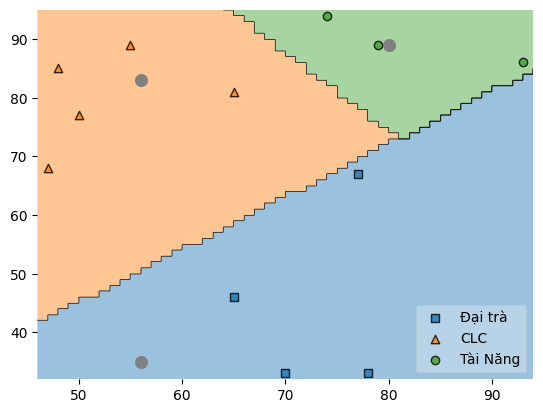

In [34]:
ax = plot_decision_regions(X_train, y_train, lrmodel)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, 
          ['Đại trà', 'CLC', 'Tài Năng'], 
           framealpha=0.3, scatterpoints=1)
plt.scatter(X_test[:, 0], X_test[:, 1], c='grey', s=70)